# How much does the formulation matter?
## Penalty-weight sensitivity of a reverse logistics problem on D-Wave quantum annealing hardware

**Author:** Ismail Zahoor, Arcada University of Applied Sciences, 2026
**Hardware run:** 5 November 2026, D-Wave Advantage_system6 quantum processor and the Leap hybrid solver
`hybrid_binary_quadratic_model_version2p`

---

### What this notebook shows

Before a business problem can run on a quantum annealer, it has to be rewritten in a special mathematical form,
and the rewriting involves a choice the business problem does not dictate: how heavily to penalize breaking a
rule. This notebook measures **how much that one choice changes the quality of the answer**, holding the problem,
the solver and the hardware constant.

It walks through the whole process in eight steps, each building on the last:

| Step | What happens | Why the next step needs it |
|---|---|---|
| 1 | Configure | Chooses between reproducing the archived run and running a new one |
| 2 | Build the problem | A realistic recycling-logistics decision with fixed, reproducible data |
| 3 | Solve it exactly with a classical solver | The **best possible answer**, against which every later result is measured |
| 4 | Rewrite it for a quantum annealer | The only input format an annealer accepts; rules become penalties |
| 5 | Check the rewriting | Proves it is still the same problem before any solver time is spent |
| 6 | Connect to D-Wave and run one test | Confirms access, processor and recording for about one second of solver time |
| 7 | Run the experiment | Varies only the penalty weight, holding everything else constant |
| 8 | Figures and tables | The results |

**This is not a test of whether quantum computers beat classical ones.** The problems are deliberately small (27
to 105 yes/no decisions) so that a conventional solver finds the provably best answer in milliseconds. That is what
makes it possible to measure exactly how far from best every other answer is.

### Two ways to run it

- **Reproduce mode (default, `RUN_EXPERIMENT = False`).** Loads the archived results of 5 November 2026 and
  regenerates every figure and table. Needs no D-Wave account and uses no solver time. Every classical result,
  including the problems and their best answers, is recomputed exactly.
- **Run mode (`RUN_EXPERIMENT = True`).** Repeats the whole experiment on D-Wave Leap. Needs a Leap account and
  about two minutes of solver time; it takes about 35 minutes, mostly queueing. Quantum results will differ in
  detail from the archive, because the hardware is probabilistic and its calibration drifts, but the pattern
  across penalty weights should recur.

*The code cells are generated from the `src/bfd` package in the accompanying repository, so the notebook and the
package always match.*

---
## Step 1 — Configure

Set `RUN_EXPERIMENT` here. Everything else in the notebook follows from it.

To run the experiment you need the **Solver API Token** from the D-Wave Leap dashboard
([cloud.dwavesys.com/leap](https://cloud.dwavesys.com/leap)), copied with its copy button. If your account has
several projects, select the right one first; tokens differ by project. Paste the **whole** token as
given; whatever it begins with is part of it. The safest place for it is Colab's Secrets panel (the key icon in
the left sidebar): add a secret named `DWAVE_API_TOKEN` and enable notebook access, so the token is never saved in
this file.

In [1]:
RUN_EXPERIMENT = False          # True: run the full experiment on D-Wave (uses ~2 min of solver allowance)
PREFERRED_QPU = "Advantage_system6"   # the processor used on 5 November 2026
OUTPUT_DIR = "outputs"

import importlib.util, os, subprocess, sys, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

# Install what Colab lacks. If Colab then asks to restart the session, restart and run again from the top.
missing = [p for p, mod in [("dwave-ocean-sdk", "dimod"), ("ortools", "ortools")]
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

def load_token():
    token = os.environ.get("DWAVE_API_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("DWAVE_API_TOKEN")
        except Exception:
            token = None
    return token

if RUN_EXPERIMENT:
    token = load_token()
    if not token:
        raise RuntimeError("RUN_EXPERIMENT is True but no DWAVE_API_TOKEN was found "
                           "(environment variable or Colab secret).")
    os.environ["DWAVE_API_TOKEN"] = token.strip()
    print(f"Token loaded (length {len(token.strip())}).")

os.makedirs(OUTPUT_DIR, exist_ok=True)

import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from IPython.display import Image, display
import dimod, ortools
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Mode: {'RUN EXPERIMENT on D-Wave' if RUN_EXPERIMENT else 'REPRODUCE from archived results'}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"dimod {dimod.__version__} | ortools {ortools.__version__}")

Mode: REPRODUCE from archived results
Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | dimod 0.12.22 | ortools 9.15.6755


---
## Step 2 — The problem

In a **circular supply chain**, used products flow back from customers to be repaired, refurbished or recycled,
instead of ending as waste. Organizing those return flows efficiently is a classic optimization problem.

**The decision.** A company collects returned products at a number of collection points. It must decide which
sorting facilities to open, and which collection point sends its returns to which facility. Opening a facility
has a fixed cost; transport cost grows with distance and return volume. Too few facilities raise transport
cost; too many raise fixed cost.

This is *facility location* for returns, also called reverse logistics network design. It was chosen over
vehicle routing because it needs far fewer yes/no variables (about `m × n + n` rather than `n²`), and because small
versions can be solved exactly, giving a known best answer to measure against.

**Decision variables (on/off switches)**
- `y_j = 1` if facility *j* is opened
- `x_ij = 1` if collection point *i* is assigned to facility *j*

**Rules that must hold**
1. Every collection point is assigned to exactly one facility
2. No collection point is assigned to a facility that is not open

| Instance | Collection points | Facilities | Binary variables | Role |
|---|---|---|---|---|
| A | 8 | 3 | 27 | Smaller check |
| B | 12 | 4 | 52 | **Main test case** |
| C | 20 | 5 | 105 | Larger check, near the limit of what fits comfortably on the processor |

The seed is fixed at 42, so the instances are identical on every run. `decode` turns any solver's switch settings
back into a business answer and checks both rules: because rules become penalties in Step 4, a solver can return a
low-scoring answer that breaks them, and such answers are never counted as results.

In [2]:
# --- generated from src/bfd/instances.py ---
"""Problem instances: reverse logistics sorting facility location.

A company collects returned products at m collection points and must decide
which of n candidate sorting facilities to open, and which facility each
collection point sends its returns to, minimizing facility opening cost plus
transport cost.

Decision variables
    y_j  = 1 if facility j is opened
    x_ij = 1 if collection point i is assigned to facility j

Instances are generated from a fixed seed, so they are identical on every
run. The instance generator must not be changed: the reference optima
(EUR 7,571 / 8,253 / 14,154) and the archived results depend on it.
"""

import numpy as np

# name: (collection points m, candidate facilities n)
INSTANCES = {"A": (8, 3), "B": (12, 4), "C": (20, 5)}
SEED = 42
COST_PER_UNIT_KM = 0.15  # EUR per returned unit per km


def build_instance(name, seed=SEED):
    """Generate instance `name` ('A', 'B' or 'C').

    Collection points lie on a 100 x 100 km grid, candidate facilities in its
    central 60 x 60 km. Transport cost is proportional to Euclidean distance
    and return volume.
    """
    m, n = INSTANCES[name]
    rng = np.random.default_rng(seed)
    points = rng.uniform(0, 100, size=(m, 2))
    facilities = rng.uniform(20, 80, size=(n, 2))
    volumes = rng.integers(50, 200, size=m)               # units per period
    open_cost = rng.integers(800, 2000, size=n)           # EUR per period
    dist = np.linalg.norm(points[:, None, :] - facilities[None, :, :], axis=2)
    transport = dist * volumes[:, None] * COST_PER_UNIT_KM
    return {"name": name, "m": m, "n": n, "transport": transport,
            "open_cost": open_cost, "volumes": volumes,
            "points": points, "facilities": facilities}


def n_variables(inst):
    """Number of binary variables: m*n assignments plus n facility switches."""
    return inst["m"] * inst["n"] + inst["n"]


def decode(sample, inst):
    """Turn switch settings into a business answer and check both constraints.

    Every solver in this study, classical or quantum, returns switch settings.
    Because the QUBO enforces constraints by penalty rather than by rule, a
    sample can score well and still be invalid, so feasibility is checked here
    rather than assumed. Infeasible samples are never counted as results.
    """
    m, n = inst["m"], inst["n"]
    assign, violations = {}, []
    for i in range(m):
        chosen = [j for j in range(n) if sample.get(f"x_{i}_{j}", 0) == 1]
        if len(chosen) != 1:
            violations.append(f"point {i} -> {len(chosen)} facilities")
        if chosen:
            assign[i] = chosen[0]
    opened = {j for j in range(n) if sample.get(f"y_{j}", 0) == 1}
    for i, j in assign.items():
        if j not in opened:
            violations.append(f"point {i} -> closed facility {j}")
    cost = sum(inst["open_cost"][j] for j in opened)
    cost += sum(inst["transport"][i][j] for i, j in assign.items())
    return {"assignment": assign, "opened": sorted(opened), "cost": float(cost),
            "feasible": len(violations) == 0, "violations": violations}


def instance_to_dict(inst, optimum=None):
    """Serializable form of an instance, for data/instances/*.json."""
    out = {
        "name": inst["name"],
        "seed": SEED,
        "collection_points": int(inst["m"]),
        "candidate_facilities": int(inst["n"]),
        "binary_variables": n_variables(inst),
        "cost_per_unit_km_eur": COST_PER_UNIT_KM,
        "points_km": np.round(inst["points"], 6).tolist(),
        "facilities_km": np.round(inst["facilities"], 6).tolist(),
        "return_volumes_units": inst["volumes"].astype(int).tolist(),
        "facility_open_cost_eur": inst["open_cost"].astype(int).tolist(),
        "transport_cost_eur": np.round(inst["transport"], 6).tolist(),
    }
    if optimum is not None:
        out["optimum"] = {
            "cost_eur": round(optimum["cost"], 4),
            "facilities_opened": [int(j) for j in optimum["opened"]],
            "assignment": {str(i): int(j) for i, j in optimum["assignment"].items()},
            "solver": "OR-Tools CP-SAT (proven optimal)",
        }
    return out

In [3]:
pd.DataFrame([{"Instance": k, "Collection points": m, "Facilities": n, "Binary variables": m * n + n}
              for k, (m, n) in INSTANCES.items()])

,Instance,Collection points,Facilities,Binary variables
0,A,8,3,27
1,B,12,4,52
2,C,20,5,105


---
## Step 3 — The exact classical optimum

Every later result is reported as an **optimality gap**: the percentage by which a solution's cost exceeds the
true minimum. Without the true minimum, quantum results could only be compared with each other.

OR-Tools CP-SAT, a widely used open-source solver, returns a proven optimum in milliseconds. Because facilities
here have no capacity limit, the optimum can also be found by trying every set of open facilities and sending each
point to its cheapest open one;
`solve_bruteforce` does this in full floating-point precision as an independent check on CP-SAT.

**Expected:** EUR 7,571 (A), EUR 8,253 (B), EUR 14,154 (C). These are deterministic and reproduce exactly. The
solve times are the honest classical baseline, which no quantum result in this notebook competes with.

In [4]:
# --- generated from src/bfd/solvers.py ---
"""Exact classical reference and helpers shared by all samplers."""

import time

import numpy as np



def solve_exact(inst):
    """Proven optimum via OR-Tools CP-SAT.

    CP-SAT works in integers, so costs are rounded to whole cents for the
    solve. The reported cost is recomputed in euros from the unrounded data.
    For instances A, B and C the result matches an exhaustive search over all
    facility subsets in full floating-point precision (see solve_bruteforce
    and tests/test_reproducibility.py), so the rounding does not change the
    optimum here.
    """
    from ortools.sat.python import cp_model
    m, n = inst["m"], inst["n"]
    scale = 100
    transport = np.rint(inst["transport"] * scale).astype(int)
    open_cost = np.rint(np.asarray(inst["open_cost"], dtype=float) * scale).astype(int)

    model = cp_model.CpModel()
    x = {(i, j): model.NewBoolVar(f"x_{i}_{j}") for i in range(m) for j in range(n)}
    y = {j: model.NewBoolVar(f"y_{j}") for j in range(n)}
    for i in range(m):
        model.AddExactlyOne(x[(i, j)] for j in range(n))
        for j in range(n):
            model.Add(x[(i, j)] <= y[j])
    model.Minimize(sum(int(open_cost[j]) * y[j] for j in range(n))
                   + sum(int(transport[i][j]) * x[(i, j)]
                         for i in range(m) for j in range(n)))

    solver = cp_model.CpSolver()
    t0 = time.perf_counter()
    status = solver.Solve(model)
    elapsed = time.perf_counter() - t0
    if status != cp_model.OPTIMAL:
        raise RuntimeError(f"CP-SAT did not prove optimality (status {status})")

    sample = {f"x_{i}_{j}": solver.Value(x[(i, j)]) for i in range(m) for j in range(n)}
    sample.update({f"y_{j}": solver.Value(y[j]) for j in range(n)})
    result = decode(sample, inst)
    result["wall_seconds"] = elapsed
    return result


def solve_bruteforce(inst):
    """Exact optimum by enumerating every non-empty set of open facilities.

    Valid because the problem is uncapacitated: once the open set is fixed,
    each point goes to its cheapest open facility. Feasible only for small n
    (2^n - 1 subsets); used as an independent check on CP-SAT.
    """
    import itertools
    n = inst["n"]
    T, F = inst["transport"], inst["open_cost"]
    best_cost, best_set = None, None
    for k in range(1, n + 1):
        for S in itertools.combinations(range(n), k):
            cost = float(sum(F[j] for j in S) + T[:, list(S)].min(axis=1).sum())
            if best_cost is None or cost < best_cost:
                best_cost, best_set = cost, list(S)
    return {"cost": best_cost, "opened": best_set}


def summarize(sampleset, inst):
    """Best feasible solution in a sampleset, and the feasible-read count.

    Returns (best, feasible_reads, total_reads). If no read is feasible,
    `best` is the lowest-energy read, marked infeasible.
    """
    best, feasible_reads, total_reads = None, 0, 0
    for rec in sampleset.data(["sample", "energy", "num_occurrences"]):
        d = decode(rec.sample, inst)
        total_reads += rec.num_occurrences
        if d["feasible"]:
            feasible_reads += rec.num_occurrences
            if best is None or d["cost"] < best["cost"]:
                best = d
    if best is None:
        best = decode(sampleset.first.sample, inst)
    return best, feasible_reads, total_reads

In [5]:
OPTIMA, rows = {}, []
for name in INSTANCES:
    inst = build_instance(name)
    r, b = solve_exact(inst), solve_bruteforce(inst)
    assert abs(r["cost"] - b["cost"]) < 1e-6, "CP-SAT and exhaustive search disagree"
    OPTIMA[name] = r["cost"]
    rows.append({"Instance": name, "Binary variables": n_variables(inst),
                 "Optimum (EUR)": round(r["cost"], 2), "Facilities opened": r["opened"],
                 "CP-SAT time (ms)": round(r["wall_seconds"] * 1000, 1),
                 "Exhaustive search agrees": True})
pd.DataFrame(rows)

,Instance,Binary variables,Optimum (EUR),Facilities opened,CP-SAT time (ms),Exhaustive search agrees
0,A,27,7571.32,[1],193.3,True
1,B,52,8253.41,"[0, 3]",7.9,True
2,C,105,14153.86,"[2, 3]",16.3,True


In [6]:
# --- generated from src/bfd/maps.py ---
"""Map of an instance and its optimal network."""


def figure_instance_map(inst, optimum, path="figure2_instance_map.png"):
    """Map of an instance and its optimal network: what is being decided."""
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(6.4, 5.8))
    pts, facs = inst["points"], inst["facilities"]
    for i, j in optimum["assignment"].items():
        ax.plot([pts[i, 0], facs[j, 0]], [pts[i, 1], facs[j, 1]],
                color="#999999", linewidth=0.9, zorder=1)
    ax.scatter(pts[:, 0], pts[:, 1], s=inst["volumes"] * 1.1, c="#4C72B0",
               alpha=0.85, edgecolor="white", linewidth=0.8, zorder=2,
               label="Collection point (size = return volume)")
    opened = set(optimum["opened"])
    for j in range(inst["n"]):
        is_open = j in opened
        ax.scatter(facs[j, 0], facs[j, 1], s=230, marker="s",
                   c="#C44E52" if is_open else "white",
                   edgecolor="#C44E52", linewidth=1.6, zorder=3)
        ax.annotate(f"F{j}", (facs[j, 0], facs[j, 1]), fontsize=8,
                    ha="center", va="center", zorder=4,
                    color="white" if is_open else "#C44E52")
    ax.scatter([], [], s=120, marker="s", c="#C44E52", label="Facility opened")
    ax.scatter([], [], s=120, marker="s", c="white", edgecolor="#C44E52",
               label="Facility not opened")
    ax.set_xlabel("km")
    ax.set_ylabel("km")
    ax.set_title(f"Instance {inst['name']}: optimal network, "
                 f"EUR {optimum['cost']:,.0f} per period", fontsize=11)
    ax.legend(frameon=False, fontsize=8, loc="upper center",
              bbox_to_anchor=(0.5, -0.12), ncol=3, columnspacing=1.2)
    ax.grid(alpha=0.2, linewidth=0.6)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    return path

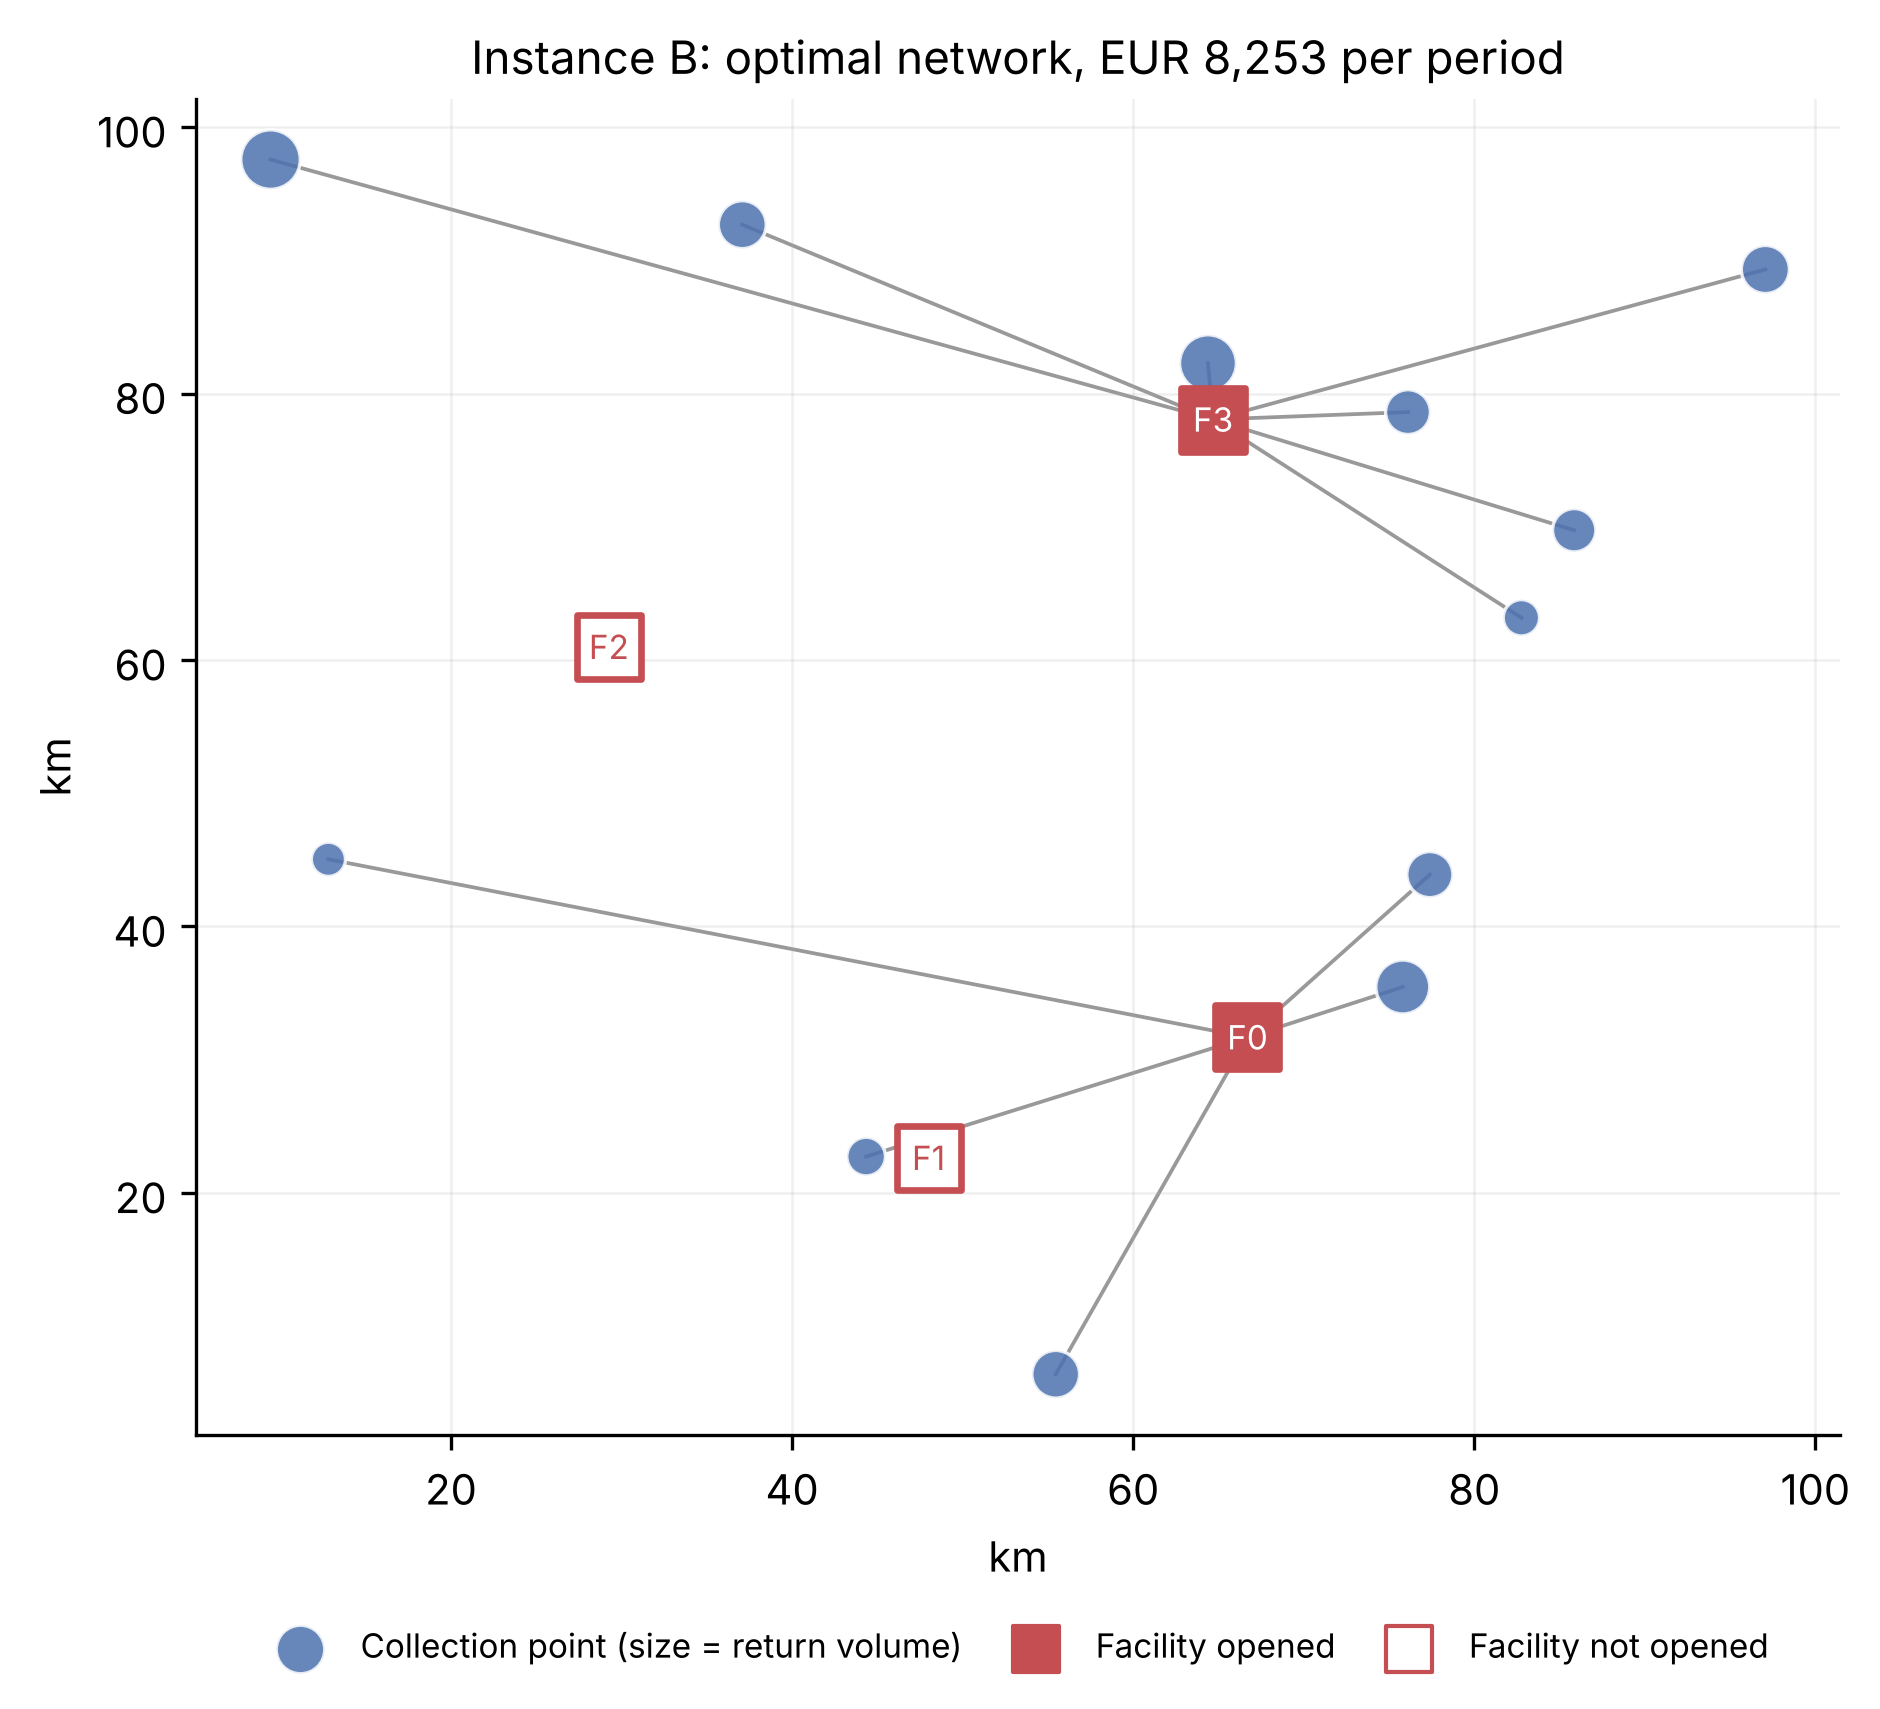

In [7]:
# What is being decided: instance B and its cheapest network.
inst_B = build_instance("B")
display(Image(figure_instance_map(inst_B, solve_exact(inst_B),
                                  os.path.join(OUTPUT_DIR, "figure2_instance_map_B.png"))))

---
## Step 4 — Translating the problem into a QUBO

A quantum annealer accepts exactly one input format, a **QUBO** (Quadratic Unconstrained Binary Optimization).
*Binary*: every variable is on or off. *Quadratic*: costs attach to single variables or to pairs. *Unconstrained*:
**there is no way to state a rule that must hold.**

So the rules become fines. Breaking a rule is made expensive rather than forbidden:

| Rule | Penalty added to the cost |
|---|---|
| Each collection point assigned exactly once | `A × (number of assignments − 1)²` |
| No assignment to a closed facility | `B × x_ij × (1 − y_j)` |

**This creates the problem the study measures.** Nothing in the business problem says how large the fines should
be. Too low, and the solver breaks rules to save money, returning cheap but invalid answers. Too high, and the
fines swamp the cost signal, returning valid but expensive answers. `penalty_scale` multiplies both fines, and it
is **the only quantity the experiment varies**.

In [8]:
# --- generated from src/bfd/qubo.py ---
"""QUBO formulation of the facility location problem.

A QUBO cannot state a rule that must hold, so both constraints become
penalties added to the cost:

    (1) each point assigned exactly once:   A * (sum_j x_ij - 1)^2
    (2) no assignment to a closed facility: B * x_ij * (1 - y_j)

Both expand into linear and pairwise terms using x^2 = x for binaries.
`penalty_scale` multiplies both weights and is the single factor varied in
the experiment. Too low and the sampler breaks constraints to save cost;
too high and the penalties swamp the cost signal.
"""

import itertools


def build_qubo(inst, penalty_scale=2.0):
    """Return (Q, offset, weights) for instance `inst`.

    A is scaled off the largest transport cost times n; B off the larger of
    the largest transport cost and the largest opening cost.
    """
    m, n = inst["m"], inst["n"]
    transport, open_cost = inst["transport"], inst["open_cost"]
    A = penalty_scale * float(transport.max()) * n
    B = penalty_scale * float(max(transport.max(), open_cost.max()))
    Q = {}

    def add(u, v, w):
        key = (u, v) if u <= v else (v, u)
        Q[key] = Q.get(key, 0.0) + w

    def x(i, j):
        return f"x_{i}_{j}"

    def y(j):
        return f"y_{j}"

    # objective
    for j in range(n):
        add(y(j), y(j), float(open_cost[j]))
    for i in range(m):
        for j in range(n):
            add(x(i, j), x(i, j), float(transport[i][j]))

    # constraint (1): one-hot assignment
    offset = 0.0
    for i in range(m):
        for j in range(n):
            add(x(i, j), x(i, j), -A)
        for j, k in itertools.combinations(range(n), 2):
            add(x(i, j), x(i, k), 2 * A)
        offset += A

    # constraint (2): assignment implies facility open
    for i in range(m):
        for j in range(n):
            add(x(i, j), x(i, j), B)
            add(x(i, j), y(j), -B)

    return Q, offset, {"A": A, "B": B}


def build_bqm(inst, penalty_scale):
    """The QUBO as a dimod BinaryQuadraticModel, plus its penalty weights."""
    import dimod
    Q, offset, weights = build_qubo(inst, penalty_scale=penalty_scale)
    return dimod.BinaryQuadraticModel.from_qubo(Q, offset=offset), weights

---
## Step 5 — Verifying the translation before spending solver time

If the QUBO described a different problem, every later number would be meaningless. Classical simulated
annealing, which runs locally at no cost, solves the QUBO for instance A; reaching the exact optimum from Step 3
proves the translation is faithful.

The share of valid reads is already well below 100 % at this setting: the first sign of the effect under study.

In [9]:
from dwave.samplers import SimulatedAnnealingSampler

inst_A = build_instance("A")
bqm, weights = build_bqm(inst_A, penalty_scale=0.25)
ss = SimulatedAnnealingSampler().sample(bqm, num_reads=1000, seed=42)
best, feasible_reads, total_reads = summarize(ss, inst_A)
print(f"QUBO terms:          {len(bqm.linear) + len(bqm.quadratic)}")
print(f"Classical optimum:   EUR {OPTIMA['A']:,.2f}")
print(f"QUBO best found:     EUR {best['cost']:,.2f}  (facilities {best['opened']})")
print(f"Valid reads:         {feasible_reads}/{total_reads}")
assert abs(best["cost"] - OPTIMA["A"]) < 1e-6, "MISMATCH: the QUBO is not the same problem"
print("\nMATCH: the QUBO and the original problem are the same problem.")

QUBO terms:          75
Classical optimum:   EUR 7,571.32
QUBO best found:     EUR 7,571.32  (facilities [1])
Valid reads:         182/1000

MATCH: the QUBO and the original problem are the same problem.


---
## Step 6 — Connecting to D-Wave, and one test run

*Skipped in reproduce mode.*

D-Wave's quantum processors (QPUs, for *quantum processing unit*) are reached over the internet through the Leap
service. Listing them is free. The notebook then selects the processor by name, because the default can change between
sessions and which processor produced a result is a reportable fact; its `chip_id` is written on every row.

**Minor embedding.** The processor's qubits are not all connected to each other, so a variable that interacts
with many others is represented by a chain of physical qubits. `EmbeddingComposite` computes this mapping. A
problem therefore uses more qubits than it has variables, and chains can break if their qubits disagree; both
are recorded.

The single test run costs about one second of QPU time and confirms credentials, embedding and logging before
the full experiment. Its row is saved to `smoke_test.csv`, separately from the experimental data, so every
billed submission is accounted for.

In [10]:
if not RUN_EXPERIMENT:
    print("Reproduce mode: no connection to D-Wave.")
else:
    from dwave.cloud import Client
    from dwave.system import DWaveSampler, EmbeddingComposite, LeapHybridSampler

    with Client.from_config() as client:
        solvers = client.get_solvers()
        qpus = [s.name for s in solvers if s.properties.get("category") == "qpu"]
        hybrids = [s.name for s in solvers if s.properties.get("category") == "hybrid"]
    print("QPUs available:   ", qpus)
    print("Hybrid available: ", hybrids)

    QPU_NAME = PREFERRED_QPU if PREFERRED_QPU in qpus else qpus[0]
    if QPU_NAME != PREFERRED_QPU:
        print(f"NOTE: {PREFERRED_QPU} is not available; using {QPU_NAME}. "
              "Results are not directly comparable with the archived run.")
    qpu = DWaveSampler(solver=QPU_NAME)
    qpu_sampler = EmbeddingComposite(qpu)
    CHIP_ID = qpu.properties.get("chip_id", QPU_NAME)
    hybrid_sampler = LeapHybridSampler()
    HYBRID_NAME = getattr(getattr(hybrid_sampler, "solver", None), "name", "LeapHybridSampler default")
    print(f"\nQPU:    {CHIP_ID} | {len(qpu.nodelist)} qubits | {qpu.properties['topology']['type']} topology")
    print(f"Hybrid: {HYBRID_NAME}")

Reproduce mode: no connection to D-Wave.


In [11]:
# --- generated from src/bfd/experiment.py ---
"""Experimental procedure: one solver call in, one schema row out.

Row schema (identical to data/results/bfd_results.csv)
    instance, n_variables, solver, penalty_scale, penalty_A, penalty_B,
    replication, chip_id, num_reads, annealing_time_us, chain_strength,
    chain_break_fraction, max_chain_length, physical_qubits,
    qpu_access_time_us, charge_time_us, wall_seconds, best_cost, feasible,
    optimality_gap_pct, feasible_fraction

Solver labels: "sa" (simulated annealing), "qpu" (Advantage QPU, automatic
chain strength), "qpu_fixed_chain" (QPU, chain strength held constant),
"hybrid" (Leap hybrid BQM solver).
"""

import time

import numpy as np
import pandas as pd


PENALTIES = [0.1, 0.25, 0.5, 1.0, 2.0, 4.0]
REPLICATIONS = 20
HYBRID_REPLICATIONS = 3
NUM_READS = 1000
ANNEALING_TIME_US = 20


def run_one(inst, optimum, solver, penalty_scale, replication,
            num_reads=NUM_READS, annealing_time=ANNEALING_TIME_US,
            chain_strength=None, qpu_sampler=None, hybrid_sampler=None,
            chip_id="", seed=None):
    """Run one solver call and return one schema row (a dict)."""
    bqm, w = build_bqm(inst, penalty_scale)
    row = {"instance": inst["name"], "n_variables": n_variables(inst),
           "solver": solver, "penalty_scale": penalty_scale,
           "penalty_A": w["A"], "penalty_B": w["B"], "replication": replication,
           "chip_id": "", "num_reads": np.nan, "annealing_time_us": np.nan,
           "chain_strength": np.nan, "chain_break_fraction": np.nan,
           "max_chain_length": np.nan, "physical_qubits": np.nan,
           "qpu_access_time_us": np.nan, "charge_time_us": np.nan}
    label = f"BFD-{inst['name']}-p{penalty_scale}-r{replication}"

    t0 = time.perf_counter()
    if solver == "sa":
        from dwave.samplers import SimulatedAnnealingSampler
        ss = SimulatedAnnealingSampler().sample(bqm, num_reads=num_reads, seed=seed)
        row["num_reads"] = num_reads
    elif solver in ("qpu", "qpu_fixed_chain"):
        kw = dict(num_reads=num_reads, annealing_time=annealing_time,
                  label=label, return_embedding=True)
        if chain_strength is not None:
            kw["chain_strength"] = chain_strength
        ss = qpu_sampler.sample(bqm, **kw)
        row["num_reads"] = num_reads
        row["annealing_time_us"] = annealing_time
        row["chip_id"] = chip_id
    elif solver == "hybrid":
        ss = hybrid_sampler.sample(bqm, label=label)
    else:
        raise ValueError(f"unknown solver {solver!r}")
    row["wall_seconds"] = time.perf_counter() - t0

    best, fr, tr = summarize(ss, inst)
    row["best_cost"] = best["cost"]
    row["feasible"] = best["feasible"]
    row["optimality_gap_pct"] = ((best["cost"] - optimum) / optimum * 100
                                 if best["feasible"] else np.nan)
    row["feasible_fraction"] = fr / tr if tr else 0.0

    # Timing: the QPU nests it under "timing"; the hybrid solver reports it at
    # the top level of sampleset.info.
    info = ss.info or {}
    timing = info.get("timing", {}) or {}
    row["qpu_access_time_us"] = timing.get("qpu_access_time",
                                           info.get("qpu_access_time", np.nan))
    row["charge_time_us"] = info.get("charge_time",
                                     timing.get("charge_time", np.nan))

    if solver.startswith("qpu"):
        ectx = info.get("embedding_context", {}) or {}
        emb = ectx.get("embedding", {})
        if emb:
            chains = [len(v) for v in emb.values()]
            row["physical_qubits"] = sum(chains)
            row["max_chain_length"] = max(chains)
        row["chain_strength"] = ectx.get("chain_strength", np.nan)
        if "chain_break_fraction" in ss.record.dtype.names:
            row["chain_break_fraction"] = float(np.average(
                ss.record.chain_break_fraction, weights=ss.record.num_occurrences))
    return row


def run_sweep(inst, optimum, solver, penalties=PENALTIES,
              replications=REPLICATIONS, progress=False, **kw):
    """All penalty settings x replications for one instance and solver."""
    rows = []
    for ps in penalties:
        for rep in range(replications):
            # simulated annealing gets a distinct, reproducible seed per cell
            seed = 1000 * rep + int(ps * 100) if solver == "sa" else None
            rows.append(run_one(inst, optimum, solver, ps, rep, seed=seed, **kw))
        if progress:
            gaps = [r["optimality_gap_pct"] for r in rows[-replications:]]
            ok = [g for g in gaps if not np.isnan(g)]
            msg = (f"mean gap {np.mean(ok):5.1f}%  ({len(ok)}/{replications} feasible)"
                   if ok else "no feasible solution")
            print(f"  instance {inst['name']}  {solver:<15} penalty {ps:<5} -> {msg}")
    return pd.DataFrame(rows)

In [12]:
if not RUN_EXPERIMENT:
    print("Reproduce mode: no test run.")
else:
    row = run_one(build_instance("A"), OPTIMA["A"], "qpu", 0.25, 0,
                  qpu_sampler=qpu_sampler, chip_id=CHIP_ID)
    pd.DataFrame([row]).to_csv(os.path.join(OUTPUT_DIR, "smoke_test.csv"), index=False)
    print(f"Best cost:      EUR {row['best_cost']:,.0f}  (optimum {OPTIMA['A']:,.0f})")
    print(f"Optimality gap: {row['optimality_gap_pct']:.1f} %")
    print(f"Valid reads:    {row['feasible_fraction']:.0%}")
    print(f"Qubits used:    {row['physical_qubits']:.0f} for 27 variables, longest chain {row['max_chain_length']:.0f}")
    print(f"Chain breaks:   {row['chain_break_fraction']:.1%}")
    print(f"QPU time:       {row['qpu_access_time_us'] / 1000:.1f} ms")

Reproduce mode: no test run.


---
## Step 7 — The experiment

*In reproduce mode this step loads the archived results instead of running anything.*

**Design.** One factor varies: `penalty_scale`, at 0.1, 0.25, 0.5, 1.0, 2.0 and 4.0. Instance, solver, processor,
read count (1,000) and annealing time (20 µs) are constant within each stage. Each condition is repeated 20 times,
because annealing is probabilistic and one run cannot separate an effect from chance.

| Stage | Solver | Instances | Repetitions | Solver time |
|---|---|---|---|---|
| 1 | Simulated annealing (classical) | A, B, C | 20 | none, runs locally (5–10 min) |
| 2 | Advantage QPU, automatic chain strength | B | 20 | ≈ 15 s |
| 3 | Advantage QPU, **fixed** chain strength | B | 20 | ≈ 15 s |
| 4 | Leap hybrid solver | B | 3 (≈ 3 s minimum each; archive: 6) | ≈ 55 s |
| 5 | Advantage QPU, automatic chain strength | A, C | 20 | ≈ 30 s |

**Why Stage 3 exists.** `EmbeddingComposite` derives chain strength from the size of the QUBO coefficients, and
the penalty weight sets those coefficients. Stage 2 therefore changes two things at once. Stage 3 fixes chain
strength at the value D-Wave's own heuristic (`uniform_torque_compensation`) gives at penalty 1.0 and holds it
across all six settings, to test whether the effect belongs to the formulation or to the embedding.

Results are written to disk after every stage, so an interrupted session loses at most one stage.

**About the archived run.** Some stages were executed more than once during the session: Stage 5 three times for
instance A and twice for instance C, and Stage 4 twice. The archive therefore holds 60 and 40 repetitions per
setting for instances A and C on the quantum processor, and 6 for the hybrid solver. All repetitions are
independent runs and are kept. The Leap platform billed 899 QPU submissions against 840 rows here; the
difference is the test run and cells interrupted before their results were saved, which the incremental saving
in this version prevents.

In [13]:
ARCHIVE_CANDIDATES = ["../data/results/bfd_results.csv", "data/results/bfd_results.csv", "bfd_results.csv"]
RESULTS_FILE = os.path.join(OUTPUT_DIR, "bfd_results.csv")
results = []

def save_progress():
    pd.concat(results, ignore_index=True).to_csv(RESULTS_FILE, index=False)

ARCHIVE_URL = ("https://raw.githubusercontent.com/ismail-lut/bfd-quantum-demonstration/"
               "main/data/results/bfd_results.csv")

if not RUN_EXPERIMENT:
    archive = next((p for p in ARCHIVE_CANDIDATES if os.path.exists(p)), None)
    if archive is None:                      # e.g. opened in Colab straight from GitHub
        try:
            import urllib.request
            urllib.request.urlretrieve(ARCHIVE_URL, "bfd_results.csv")
            archive = "bfd_results.csv"
            print(f"Downloaded archived results from {ARCHIVE_URL}")
        except Exception as e:
            print(f"Could not download archived results ({e}).")
    if archive is None and IN_COLAB:
        from google.colab import files
        print("Upload data/results/bfd_results.csv from the repository:")
        archive = next(iter(files.upload()))
    if archive is None:
        raise FileNotFoundError("Archived results not found; expected data/results/bfd_results.csv")
    print(f"Loaded archived results from {archive}")
else:
    print("Stage 1: simulated annealing, all instances (no solver time)")
    for name in INSTANCES:
        results.append(run_sweep(build_instance(name), OPTIMA[name], "sa", progress=True))
    save_progress()

Loaded archived results from ../data/results/bfd_results.csv


In [14]:
if RUN_EXPERIMENT:
    print("Stage 2: QPU, instance B")
    results.append(run_sweep(build_instance("B"), OPTIMA["B"], "qpu", progress=True,
                             qpu_sampler=qpu_sampler, chip_id=CHIP_ID))
    save_progress()

    print("Stage 3: QPU with fixed chain strength, instance B")
    from dwave.embedding.chain_strength import uniform_torque_compensation
    FIXED_CHAIN_STRENGTH = float(uniform_torque_compensation(build_bqm(build_instance("B"), 1.0)[0]))
    print(f"  fixed chain strength = {FIXED_CHAIN_STRENGTH:,.0f}  (archived run: 45,843)")
    results.append(run_sweep(build_instance("B"), OPTIMA["B"], "qpu_fixed_chain", progress=True,
                             chain_strength=FIXED_CHAIN_STRENGTH,
                             qpu_sampler=qpu_sampler, chip_id=CHIP_ID))
    save_progress()

    print("Stage 4: hybrid solver, instance B")
    results.append(run_sweep(build_instance("B"), OPTIMA["B"], "hybrid", replications=HYBRID_REPLICATIONS,
                             progress=True, hybrid_sampler=hybrid_sampler))
    save_progress()

    print("Stage 5: QPU, instances A and C")
    for name in ["A", "C"]:
        results.append(run_sweep(build_instance(name), OPTIMA[name], "qpu", progress=True,
                                 qpu_sampler=qpu_sampler, chip_id=CHIP_ID))
        save_progress()

---
## Step 8 — Figures and tables

Everything below reads only the results table, so it uses no solver time and can be rerun freely. The analysis is
descriptive: with a handful of settings, the aim is to show the size and shape of the effect, not to test
hypotheses statistically.

**Cost and gap statistics are computed over feasible runs only.** A run that returned no valid solution has no
meaningful cost; an invalid configuration can even cost less than the optimum. The share of valid reads is
computed over all runs. (Averaging cost over all runs instead would give, for example, EUR 5,705 for the quantum
processor at penalty 0.1 on instance B: below the best possible cost of EUR 8,253, which no valid answer can be.)

In [15]:
# --- generated from src/bfd/analysis.py ---
"""Summary statistics, figure and tables.

Cost and gap statistics are computed over FEASIBLE runs only: a run that
returned no feasible solution has no meaningful cost (an invalid
configuration can cost less than the optimum). Feasible-read share is
computed over ALL runs, since a run with zero valid reads is itself data.

Averaging cost over all runs instead would report, for example, EUR 5,705
for the QPU at penalty 0.1 on instance B: below the optimum of EUR 8,253,
which no valid solution can be.
"""

import numpy as np
import pandas as pd

SOLVER_LABEL = {"sa": "Simulated annealing (classical)",
                "qpu": "D-Wave Advantage QPU",
                "qpu_fixed_chain": "QPU, fixed chain strength",
                "hybrid": "Leap hybrid solver"}
STYLE = {"sa":              dict(color="#4C72B0", marker="o", linestyle="--"),
         "qpu":             dict(color="#C44E52", marker="s", linestyle="-"),
         "qpu_fixed_chain": dict(color="#8172B2", marker="D", linestyle="-."),
         "hybrid":          dict(color="#55A868", marker="^", linestyle=":")}
ORDER = ["sa", "qpu", "qpu_fixed_chain", "hybrid"]


def load_results(path):
    """Read a results CSV, normalizing the `feasible` column to bool."""
    df = pd.read_csv(path)
    if df["feasible"].dtype != bool:
        df["feasible"] = df["feasible"].astype(str).str.lower().isin(["true", "1"])
    return df


def aggregate(df):
    """One row per (instance, solver, penalty_scale)."""
    out = []
    for (inst, solver, ps), s in df.groupby(["instance", "solver", "penalty_scale"]):
        f = s[s.feasible]
        out.append({
            "instance": inst, "solver": solver, "penalty_scale": ps,
            "n_runs": len(s), "n_feasible_runs": len(f),
            "mean_cost": f.best_cost.mean() if len(f) else np.nan,
            "mean_gap": f.optimality_gap_pct.mean() if len(f) else np.nan,
            "sd_gap": f.optimality_gap_pct.std() if len(f) > 1 else np.nan,
            "min_gap": f.optimality_gap_pct.min() if len(f) else np.nan,
            "max_gap": f.optimality_gap_pct.max() if len(f) else np.nan,
            "feasible_fraction": s.feasible_fraction.mean(),
            "chain_break": s.chain_break_fraction.mean(),
            "qpu_us": s.qpu_access_time_us.mean(),
            "physical_qubits": s.physical_qubits.mean(),
            "max_chain": s.max_chain_length.max()})
    return pd.DataFrame(out)


def figure_1(df, instance="B", path="figure1_penalty_sensitivity.png"):
    """Optimality gap and feasible-read share against penalty scale."""
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    g = aggregate(df)
    g = g[g.instance == instance]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.4, 7.4), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})
    for solver in ORDER:
        s = g[g.solver == solver].sort_values("penalty_scale")
        if s.empty:
            continue
        st = STYLE[solver]
        ok = s.dropna(subset=["mean_gap"])
        rel = ok[ok.n_feasible_runs >= 0.5 * ok.n_runs]
        unrel = ok[ok.n_feasible_runs < 0.5 * ok.n_runs]
        ax1.plot(rel.penalty_scale, rel.mean_gap, label=SOLVER_LABEL[solver],
                 linewidth=1.8, markersize=6, **st)
        if len(unrel):
            ax1.plot(unrel.penalty_scale, unrel.mean_gap, linestyle="none",
                     marker=st["marker"], markersize=6, markerfacecolor="white",
                     markeredgecolor=st["color"], markeredgewidth=1.4)
        if ok.sd_gap.notna().any():
            ax1.fill_between(rel.penalty_scale,
                             rel.mean_gap - rel.sd_gap.fillna(0),
                             rel.mean_gap + rel.sd_gap.fillna(0),
                             color=st["color"], alpha=0.14, linewidth=0)
        dead = s[s.n_feasible_runs == 0]
        if len(dead):
            j = 1.0 + 0.055 * (ORDER.index(solver) - 1.5)  # keep series visible
            ax1.plot(dead.penalty_scale * j, np.zeros(len(dead)), linestyle="none",
                     marker="x", markersize=8, markeredgewidth=1.8,
                     color=st["color"], clip_on=False)
        ax2.plot(s.penalty_scale, s.feasible_fraction * 100,
                 linewidth=1.8, markersize=6, **st)

    ax1.axhline(0, color="black", linewidth=1.0, zorder=1)
    ax1.annotate("Classical optimum (0% gap)", xy=(0.985, 0.0),
                 xycoords=("axes fraction", "data"), xytext=(0, 6),
                 textcoords="offset points", fontsize=8, style="italic",
                 ha="right", va="bottom", color="#333333")
    n_vars = int(df[df.instance == instance].n_variables.iloc[0])
    ax1.set_ylabel("Optimality gap (%)")
    ax1.set_title(f"Solution quality against penalty weight — instance {instance} "
                  f"({n_vars} variables)", fontsize=11, pad=10)
    ax1.grid(alpha=0.25, linewidth=0.6)
    h, lab = ax1.get_legend_handles_labels()
    h += [Line2D([], [], linestyle="none", marker="x", color="#555555",
                 markersize=8, markeredgewidth=1.8),
          Line2D([], [], linestyle="none", marker="o", markerfacecolor="white",
                 markeredgecolor="#555555", markeredgewidth=1.4, markersize=6)]
    lab += ["no feasible solution in any run", "feasible in a minority of runs"]
    ax1.legend(h, lab, frameon=False, fontsize=8.5, loc="upper left",
               handletextpad=0.8)
    ax2.set_ylabel("Feasible reads (%)")
    ax2.set_xlabel("Penalty scale")
    ax2.set_xscale("log")
    ax2.set_ylim(-5, 105)
    ax2.grid(alpha=0.25, linewidth=0.6)
    ticks = sorted(g.penalty_scale.unique())
    ax2.set_xticks(ticks)
    ax2.set_xticklabels([f"{t:g}" for t in ticks])
    ax2.minorticks_off()
    fig.align_ylabels([ax1, ax2])
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    return path


def table_1(df, instance="B"):
    """Per-penalty detail for one instance."""
    g = aggregate(df)
    g = g[g.instance == instance].copy()
    out = pd.DataFrame({
        "Solver": g.solver.map(SOLVER_LABEL),
        "Penalty": g.penalty_scale,
        "Runs": g.n_runs, "Feasible runs": g.n_feasible_runs,
        "Mean cost (EUR)": g.mean_cost.round(0),
        "Mean gap (%)": g.mean_gap.round(1), "SD (pp)": g.sd_gap.round(1),
        "Best (%)": g.min_gap.round(1), "Worst (%)": g.max_gap.round(1),
        "Feasible reads (%)": (g.feasible_fraction * 100).round(0),
        "Chain breaks (%)": (g.chain_break * 100).round(1),
        "QPU time (ms)": (g.qpu_us / 1000).round(1)})
    return out.sort_values(["Solver", "Penalty"]).reset_index(drop=True)


def table_2(df):
    """Best and worst penalty setting per instance and solver."""
    g = aggregate(df).dropna(subset=["mean_gap"])
    rows = []
    for (i, s), x in g.groupby(["instance", "solver"]):
        b, w = x.loc[x.mean_gap.idxmin()], x.loc[x.mean_gap.idxmax()]
        rows.append({"Instance": i,
                     "Variables": int(df[df.instance == i].n_variables.iloc[0]),
                     "Solver": SOLVER_LABEL[s], "Replications": int(x.n_runs.max()),
                     "Best penalty": b.penalty_scale,
                     "Best gap (%)": round(b.mean_gap, 1),
                     "Worst penalty": w.penalty_scale,
                     "Worst gap (%)": round(w.mean_gap, 1),
                     "Spread (pp)": round(w.mean_gap - b.mean_gap, 1)})
    return pd.DataFrame(rows).sort_values(["Instance", "Solver"]).reset_index(drop=True)


def table_embedding(df):
    """Minor-embedding overhead by instance, over all QPU runs."""
    q = df[df.solver.str.startswith("qpu")]
    e = q.groupby("instance").agg(
        logical_variables=("n_variables", "first"),
        physical_qubits_mean=("physical_qubits", "mean"),
        longest_chain=("max_chain_length", "max"),
        chain_break_fraction_mean=("chain_break_fraction", "mean"),
        qpu_runs=("solver", "size"))
    e["qubits_per_variable"] = e.physical_qubits_mean / e.logical_variables
    return e.round(2).reset_index()


def table_usage(df):
    """Solver calls and recorded solver time, by solver."""
    rows = []
    for solver, s in df.groupby("solver"):
        rows.append({"solver": solver, "calls": len(s),
                     "qpu_access_time_s": round(s.qpu_access_time_us.sum() / 1e6, 3),
                     "charge_time_s": round(s.charge_time_us.sum() / 1e6, 3)})
    return pd.DataFrame(rows)


def chain_break_summary(df):
    """Chain breaks by instance and solver, in percent of chains per read.

    chain_break_fraction is the share of chains broken in a read, averaged
    over the reads of one submission. Report it unrounded: values here are
    of order 0.01 %, which rounds to 0.0 % but is not zero.
    """
    q = df[df.solver.str.startswith("qpu")]
    out = q.groupby(["instance", "solver"]).chain_break_fraction.agg(
        submissions="size",
        submissions_with_breaks=lambda x: int((x > 0).sum()),
        mean_pct=lambda x: x.mean() * 100,
        max_pct=lambda x: x.max() * 100)
    return out.round(4).reset_index()

In [16]:
data = load_results(archive if not RUN_EXPERIMENT else RESULTS_FILE)
print(f"{len(data)} runs\n")
print(data.groupby(["solver", "instance"]).size().rename("runs").to_string())
print(f"\nQPU access time recorded: {data.qpu_access_time_us.sum() / 1e6:.1f} s")
print(f"Hybrid time charged:      {data.charge_time_us.sum() / 1e6:.1f} s")

1236 runs



solver           instance
hybrid           B            36
qpu              A           360
                 B           120
                 C           240
qpu_fixed_chain  B           120
sa               A           120
                 B           120
                 C           120

QPU access time recorded: 106.1 s
Hybrid time charged:      107.7 s


### Figure 1 — Solution quality against penalty weight, instance B

Shaded bands show one standard deviation across repetitions. A cross on the baseline marks a condition in which no
repetition found a valid solution; a hollow marker, one valid in only a minority of repetitions. Low penalties
fail by returning invalid answers; high penalties return valid answers of steadily worse cost.

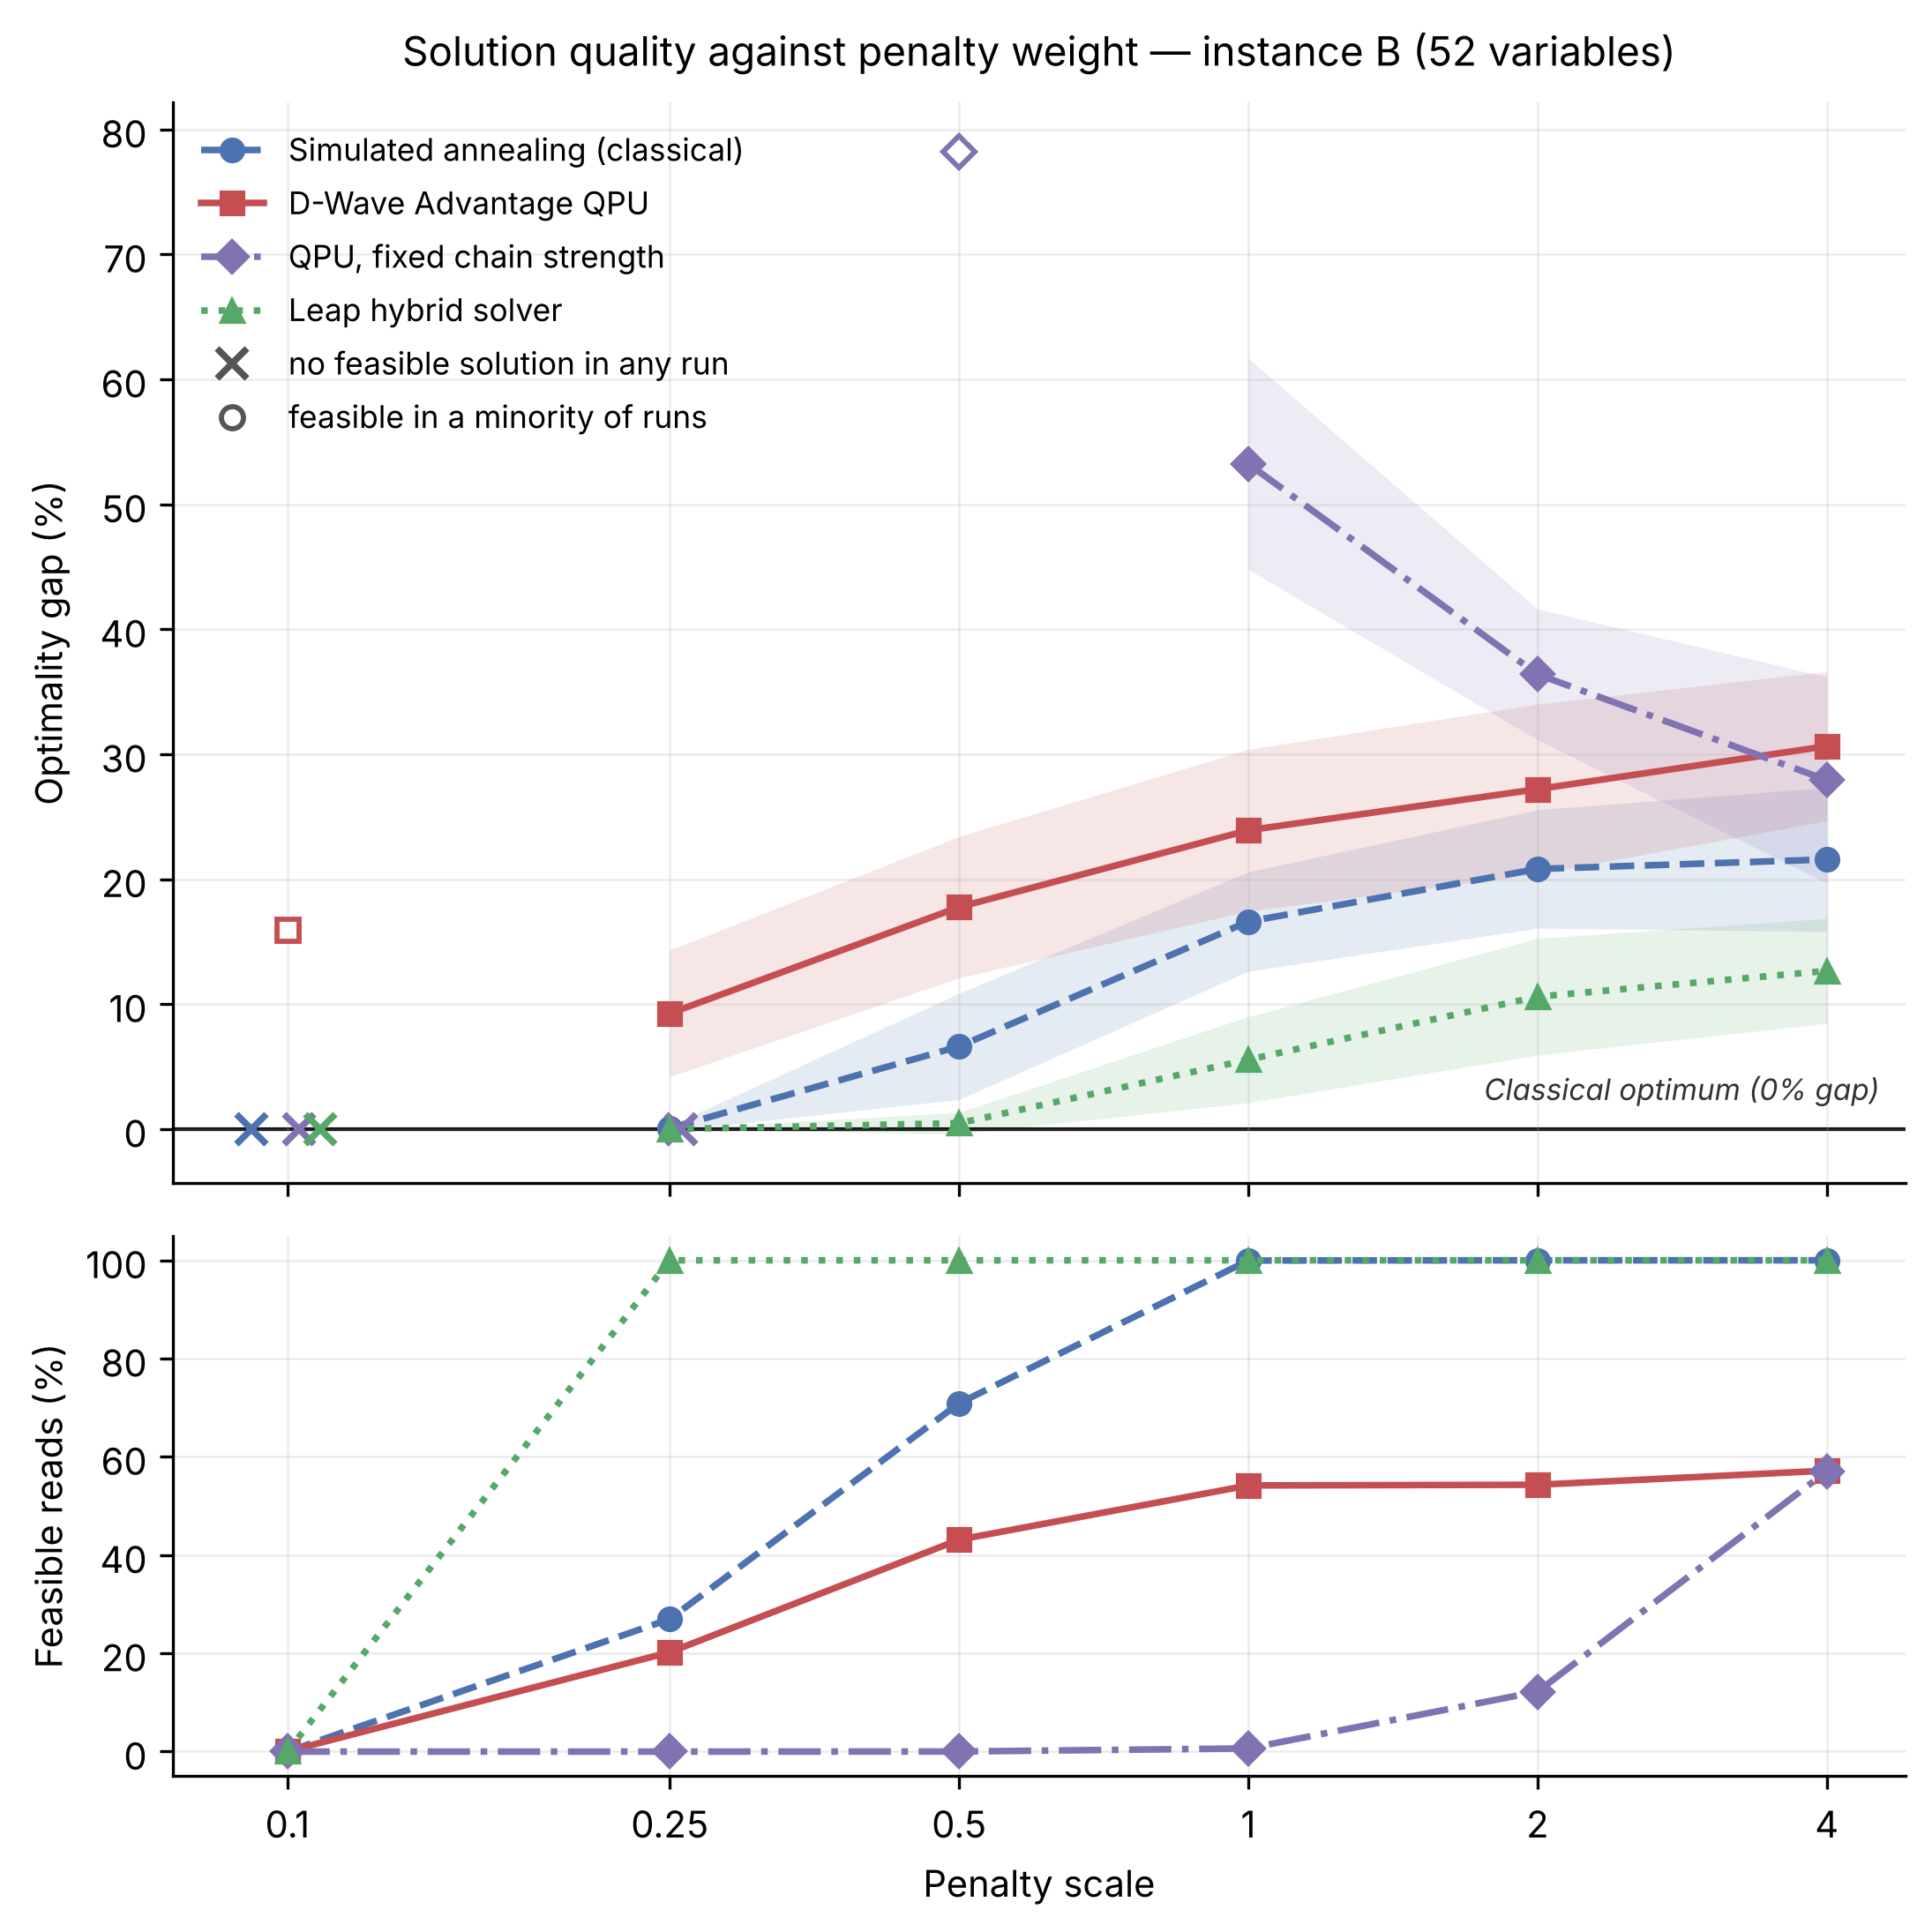

In [17]:
display(Image(figure_1(data, "B", os.path.join(OUTPUT_DIR, "figure1_penalty_sensitivity.png"))))

### Table 1 — Instance B, by penalty setting and solver

In [18]:
t1 = table_1(data, "B")
t1.to_csv(os.path.join(OUTPUT_DIR, "table1_instance_B.csv"), index=False)
t1

,Solver,Penalty,Runs,Feasible runs,Mean cost (EUR),Mean gap (%),SD (pp),Best (%),Worst (%),Feasible reads (%),Chain breaks (%),QPU time (ms)
0,D-Wave Advantage QPU,0.10,20,8,9571.0,16.0,9.3,3.5,26.8,0.0,0.0,130.8
1,D-Wave Advantage QPU,0.25,20,20,9017.0,9.3,5.1,0.0,17.8,20.0,0.0,129.0
2,D-Wave Advantage QPU,0.50,20,20,9719.0,17.8,5.7,5.5,23.6,43.0,0.0,127.3
3,D-Wave Advantage QPU,1.00,20,20,10227.0,23.9,6.5,8.4,33.1,54.0,0.0,123.8
4,D-Wave Advantage QPU,2.00,20,20,10499.0,27.2,6.8,11.9,35.5,54.0,0.0,123.0
5,D-Wave Advantage QPU,4.00,20,20,10783.0,30.6,6.0,16.5,40.1,57.0,0.0,127.3
6,Leap hybrid solver,0.10,6,0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
7,Leap hybrid solver,0.25,6,6,8253.0,0.0,0.0,0.0,0.0,100.0,NaN,NaN
8,Leap hybrid solver,0.50,6,6,8292.0,0.5,0.9,0.0,2.2,100.0,NaN,NaN
9,Leap hybrid solver,1.00,6,6,8712.0,5.6,3.4,1.5,11.0,100.0,NaN,NaN


### Table 2 — Robustness across instances

The spread column states the finding in one number: how far solution quality moves on an identical problem when
only the penalty weight changes.

In [19]:
t2 = table_2(data)
t2.to_csv(os.path.join(OUTPUT_DIR, "table2_robustness.csv"), index=False)
t2

,Instance,Variables,Solver,Replications,Best penalty,Best gap (%),Worst penalty,Worst gap (%),Spread (pp)
0,A,27,D-Wave Advantage QPU,60,0.25,0.0,4.0,7.7,7.7
1,A,27,Simulated annealing (classical),20,0.25,0.0,4.0,3.1,3.1
2,B,52,D-Wave Advantage QPU,20,0.25,9.3,4.0,30.6,21.4
3,B,52,Leap hybrid solver,6,0.25,0.0,4.0,12.7,12.7
4,B,52,"QPU, fixed chain strength",20,4.00,27.9,0.5,78.2,50.3
5,B,52,Simulated annealing (classical),20,0.25,0.1,4.0,21.6,21.5
6,C,105,D-Wave Advantage QPU,40,0.10,22.5,4.0,36.5,14.0
7,C,105,Simulated annealing (classical),20,0.25,12.2,4.0,32.7,20.5


### Table 3 — Minor-embedding overhead

In [20]:
t3 = table_embedding(data)
t3.to_csv(os.path.join(OUTPUT_DIR, "table3_embedding.csv"), index=False)
t3

,instance,logical_variables,physical_qubits_mean,longest_chain,chain_break_fraction_mean,qpu_runs,qubits_per_variable
0,A,27,32.33,3.0,0.0,360,1.20
1,B,52,78.06,7.0,0.0,240,1.50
2,C,105,198.43,11.0,0.0,240,1.89


### Chain breaks

Reported unrounded, because they are of order 0.01 % of chains per read: small enough to round to 0.0 % in
Table 3, but not zero.

In [21]:
chain_break_summary(data)

,instance,solver,submissions,submissions_with_breaks,mean_pct,max_pct
0,A,qpu,360,196,0.0039,0.0519
1,B,qpu,120,118,0.0138,0.1019
2,B,qpu_fixed_chain,120,113,0.0071,0.0269
3,C,qpu,240,240,0.0239,0.3276


### Is the quantum processor more sensitive than the classical algorithm?

A quantum processor works with limited analog precision, so one might expect large penalties, which squeeze the
real cost differences into a small part of its range, to hurt it more than a classical algorithm solving the same
input. In the archived run they did not: the quantum processor is uniformly somewhat worse, with no widening
trend as the penalty grows.

In [22]:
g = aggregate(data)
p = g[(g.instance == "B") & g.solver.isin(["sa", "qpu"])].pivot(
    index="penalty_scale", columns="solver", values="mean_gap")
p["qpu_minus_sa_pp"] = p["qpu"] - p["sa"]
p.round(1)

solver,qpu,sa,qpu_minus_sa_pp
penalty_scale,,,
0.10,16.0,NaN,NaN
0.25,9.3,0.1,9.2
0.50,17.8,6.6,11.1
1.00,23.9,16.6,7.3
2.00,27.2,20.8,6.4
4.00,30.6,21.6,9.1


---
## What the results show

1. **The whole process works.** A recycling-logistics problem was rewritten, checked against its known best answer
   and solved on a quantum processor, which found the best answer on the smallest instance.
2. **The penalty weight alone moved answer quality by 21.4 percentage points** on instance B on the quantum
   processor, with everything else held constant, and by 21.5 points for classical simulated annealing.
3. **The failures look very different.** Penalties too small give no valid answer, which is obvious. Penalties too
   large give valid answers 20 to 30 % more expensive than necessary, and nothing in the output says so.
4. **The hardware did not make the effect worse.** The quantum processor was 6 to 11 points behind simulated
   annealing at every setting, with no widening trend.
5. **On real hardware, penalties and chain strength are tied together.** Holding chain strength fixed reversed the
   direction of the effect and widened it to 50.3 points.
6. **Broken chains do not explain it.** They were rare (on average 0.012 % of chains per read, at most 0.33 %) and
   did not change with the setting, while answer quality changed by tens of points.
7. **The best setting does not carry over between instances**, and **the conventional exact solver was best at
   every size.**

**Limits.** One problem type, three small synthetic instances, one way of setting the penalties, one processor and
one session. The numbers show how large the effect can be; they do not estimate its size for real networks.